# Import Library

In [8]:
import pandas as pd
import numpy as np
import re
import string
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
import nltk

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Embedding, LSTM, Conv1D, GlobalMaxPooling1D, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

# Load Dataset

In [9]:
train_df = pd.read_csv("/kaggle/input/datasets/hiteshyadavx/tweet-emotion-recognition/train.csv")
val_df   = pd.read_csv("/kaggle/input/datasets/hiteshyadavx/tweet-emotion-recognition/val.csv")
test_df  = pd.read_csv("/kaggle/input/datasets/hiteshyadavx/tweet-emotion-recognition/test.csv")

print(train_df.shape, val_df.shape, test_df.shape)

(16000, 2) (2000, 2) (2000, 2)


# Pre-Processing

In [12]:
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+|https\S+", '', text)
    text = re.sub(r'@\w+|#\w+', '', text)
    text = re.sub(r'\d+', '', text)
    text = text.translate(str.maketrans('', '', string.punctuation))
    
    words = text.split()
    words = [stemmer.stem(word) for word in words if word not in stop_words]
    
    return " ".join(words)

train_df['clean_text'] = train_df['text'].apply(clean_text)
val_df['clean_text']   = val_df['text'].apply(clean_text)
test_df['clean_text']  = test_df['text'].apply(clean_text)

# Feature Extraction

In [13]:
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1,2))

X_train = tfidf.fit_transform(train_df['clean_text'])
X_val   = tfidf.transform(val_df['clean_text'])
X_test  = tfidf.transform(test_df['clean_text'])

y_train = train_df['label']
y_val   = val_df['label']
y_test  = test_df['label']

# Train Model ML

In [14]:
# LOGISTIC REGRESSION

lr_model = LogisticRegression(max_iter=200)
lr_model.fit(X_train, y_train)

y_val_pred_lr = lr_model.predict(X_val)

print("=== Logistic Regression ===")
print("Accuracy:", accuracy_score(y_val, y_val_pred_lr))
print(classification_report(y_val, y_val_pred_lr))

=== Logistic Regression ===
Accuracy: 0.87
              precision    recall  f1-score   support

           0       0.88      0.93      0.90       550
           1       0.86      0.94      0.90       704
           2       0.86      0.65      0.74       178
           3       0.90      0.84      0.87       275
           4       0.87      0.78      0.82       212
           5       0.88      0.64      0.74        81

    accuracy                           0.87      2000
   macro avg       0.87      0.80      0.83      2000
weighted avg       0.87      0.87      0.87      2000



In [15]:
# NAIVE BAYES

nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

y_val_pred_nb = nb_model.predict(X_val)

print("=== Naive Bayes ===")
print("Accuracy:", accuracy_score(y_val, y_val_pred_nb))
print(classification_report(y_val, y_val_pred_nb))

=== Naive Bayes ===
Accuracy: 0.789
              precision    recall  f1-score   support

           0       0.77      0.92      0.84       550
           1       0.74      0.97      0.84       704
           2       0.95      0.30      0.46       178
           3       0.94      0.65      0.77       275
           4       0.86      0.64      0.74       212
           5       1.00      0.21      0.35        81

    accuracy                           0.79      2000
   macro avg       0.88      0.62      0.67      2000
weighted avg       0.82      0.79      0.77      2000



# Tokenization

In [16]:
max_words = 5000
max_len = 50

tokenizer = Tokenizer(num_words=max_words)
tokenizer.fit_on_texts(train_df['clean_text'])

X_train_seq = pad_sequences(tokenizer.texts_to_sequences(train_df['clean_text']), maxlen=max_len)
X_val_seq   = pad_sequences(tokenizer.texts_to_sequences(val_df['clean_text']), maxlen=max_len)
X_test_seq  = pad_sequences(tokenizer.texts_to_sequences(test_df['clean_text']), maxlen=max_len)

# Train Model DL

In [17]:
# LSTM 

lstm_model = Sequential([
    Embedding(max_words, 64, input_length=max_len),
    LSTM(32),
    Dropout(0.5),
    Dense(32, activation='relu'),
    Dense(6, activation='softmax')
])

lstm_model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

history_lstm = lstm_model.fit(
    X_train_seq, y_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_val_seq, y_val),
    callbacks=[early_stop]
)

lstm_pred = np.argmax(lstm_model.predict(X_val_seq), axis=1)

print("=== LSTM ===")
print("Accuracy:", accuracy_score(y_val, lstm_pred))
print(classification_report(y_val, lstm_pred))

Epoch 1/10


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.3874 - loss: 1.5187 - val_accuracy: 0.7195 - val_loss: 0.7760
Epoch 2/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.7815 - loss: 0.6198 - val_accuracy: 0.8650 - val_loss: 0.3961
Epoch 3/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.9046 - loss: 0.2876 - val_accuracy: 0.8745 - val_loss: 0.3568
Epoch 4/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.9346 - loss: 0.2003 - val_accuracy: 0.8885 - val_loss: 0.3675
Epoch 5/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.9467 - loss: 0.1535 - val_accuracy: 0.8855 - val_loss: 0.3689
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
=== LSTM ===
Accuracy: 0.8745
              precision    recall  f1-score   support

           0       0.92      0.93      0.92       550
           1       0.94      0.86      0.90       704
           2       0.73      0.75      0.74       178
           3       0.84      0.93      0.88       275
           4       0

In [20]:
# CNN

cnn_model = Sequential([
    Embedding(max_words, 64, input_length=max_len),
    Conv1D(128, 5, activation='relu'),
    GlobalMaxPooling1D(),
    Dropout(0.5),
    Dense(32, activation='relu'),
    Dense(6, activation='softmax')
])

cnn_model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

history_cnn = cnn_model.fit(
    X_train_seq, y_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_val_seq, y_val),
    callbacks=[early_stop]
)

cnn_pred = np.argmax(cnn_model.predict(X_val_seq), axis=1)

print("=== CNN ===")
print("Accuracy:", accuracy_score(y_val, cnn_pred))
print(classification_report(y_val, cnn_pred))

Epoch 1/10


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.4208 - loss: 1.4427 - val_accuracy: 0.8905 - val_loss: 0.3285
Epoch 2/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8946 - loss: 0.3158 - val_accuracy: 0.9085 - val_loss: 0.2549
Epoch 3/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9293 - loss: 0.2014 - val_accuracy: 0.9060 - val_loss: 0.2519
Epoch 4/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9518 - loss: 0.1385 - val_accuracy: 0.9035 - val_loss: 0.2848
Epoch 5/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9635 - loss: 0.1042 - val_accuracy: 0.9005 - val_loss: 0.3095
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
=== CNN ===
Accuracy: 0.906
              precision    recall  f1-score   support

           0       0.94      0.93      0.93       550
           1       0.95      0.92      0.93       704
           2       0.79      0.85      0.82       178
           3       0.88      0.95      0.91       275
           4       0.85     

# Model Evaluation & Visualization

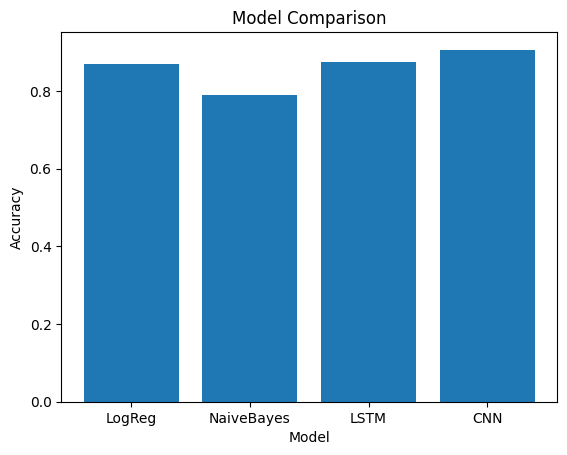

In [21]:
results = {
    "LogReg": accuracy_score(y_val, y_val_pred_lr),
    "NaiveBayes": accuracy_score(y_val, y_val_pred_nb),
    "LSTM": accuracy_score(y_val, lstm_pred),
    "CNN": accuracy_score(y_val, cnn_pred)
}

plt.figure()
plt.bar(results.keys(), results.values())
plt.title("Model Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.show()

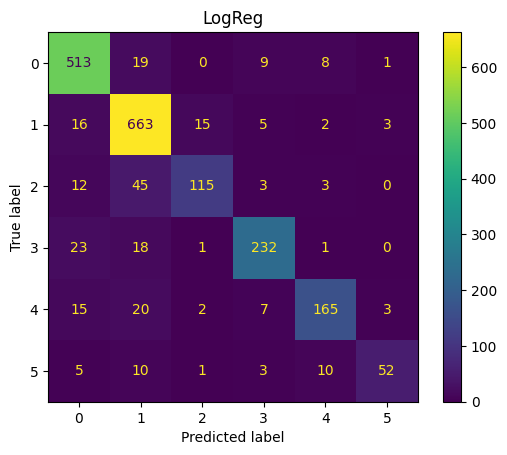

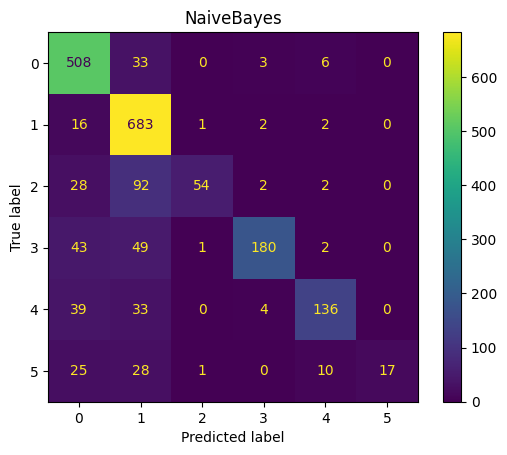

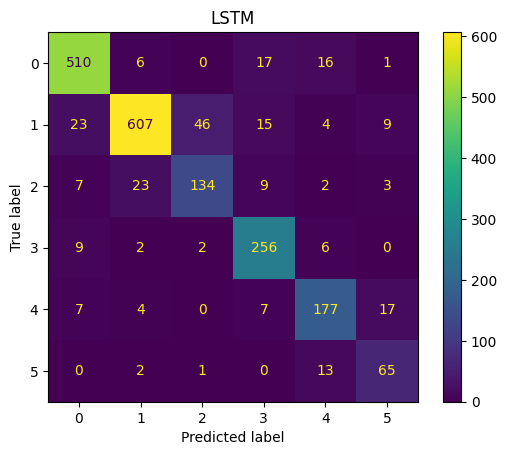

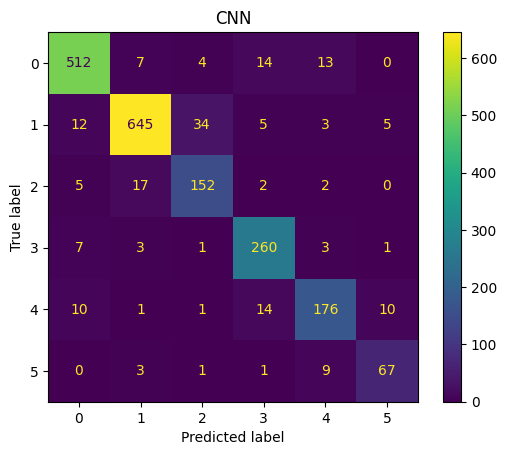

In [22]:
def plot_cm(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(cm)
    disp.plot()
    plt.title(title)
    plt.show()

plot_cm(y_val, y_val_pred_lr, "LogReg")
plot_cm(y_val, y_val_pred_nb, "NaiveBayes")
plot_cm(y_val, lstm_pred, "LSTM")
plot_cm(y_val, cnn_pred, "CNN")

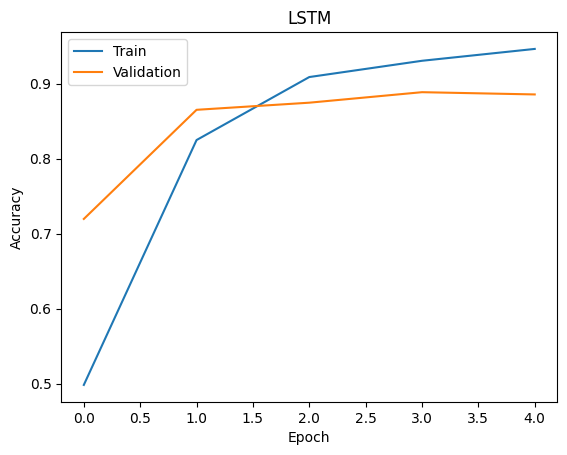

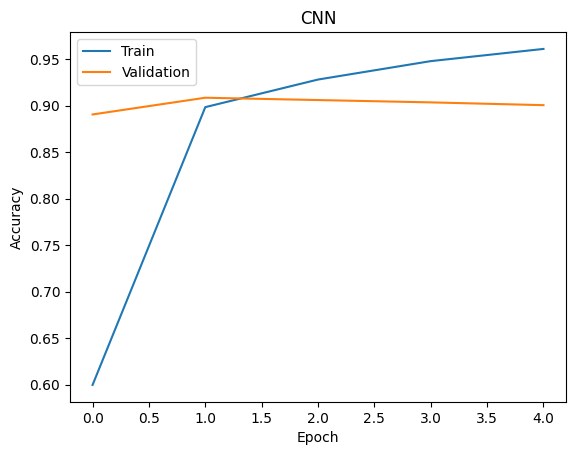

In [23]:
def plot_history(history, title):
    plt.figure()
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend(["Train", "Validation"])
    plt.show()

plot_history(history_lstm, "LSTM")
plot_history(history_cnn, "CNN")